# Flight Price Prediction – EDA and Feature Engineering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)


## 1. Load Data

In [2]:
# Keep Clean_Dataset.csv in the same folder as this notebook
df = pd.read_csv("Clean_Dataset.csv")
df.head()

df.tail()


,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585


In [3]:
print("Shape:", df.shape)
print(df.columns.tolist())

df.info()


Shape: (300153, 12)
['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)


In [4]:
df.describe()


,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


## 2. Data Cleaning

In [5]:
df.isnull().sum()

print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()


Duplicate rows: 0


In [6]:
# Remove the extra index column if it is present
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]
df.head()

for col in df.select_dtypes(include="object").columns:
    print("\\n", col, ":", df[col].nunique(), "unique values")


\n airline : 6 unique values
\n flight : 1561 unique values
\n source_city : 6 unique values
\n departure_time : 6 unique values
\n stops : 3 unique values
\n arrival_time : 6 unique values
\n destination_city : 6 unique values
\n class : 2 unique values


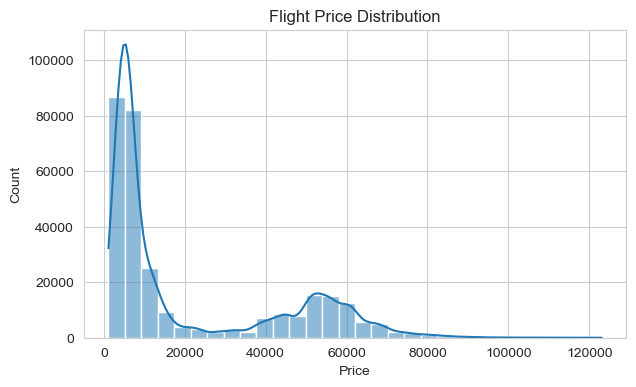

In [7]:
df["price"].describe()

plt.figure(figsize=(7, 4))
sns.histplot(df["price"], bins=30, kde=True)
plt.title("Flight Price Distribution")
plt.xlabel("Price")
plt.show()


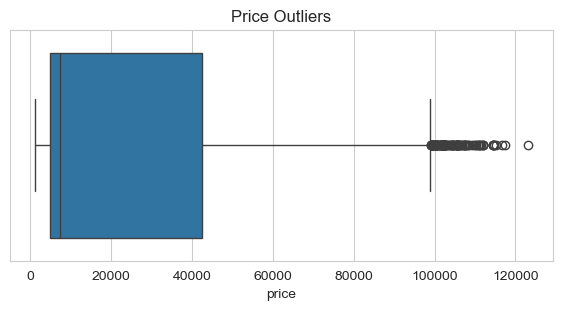

In [8]:
plt.figure(figsize=(7, 3))
sns.boxplot(x=df["price"])
plt.title("Price Outliers")
plt.show()


## 3. EDA

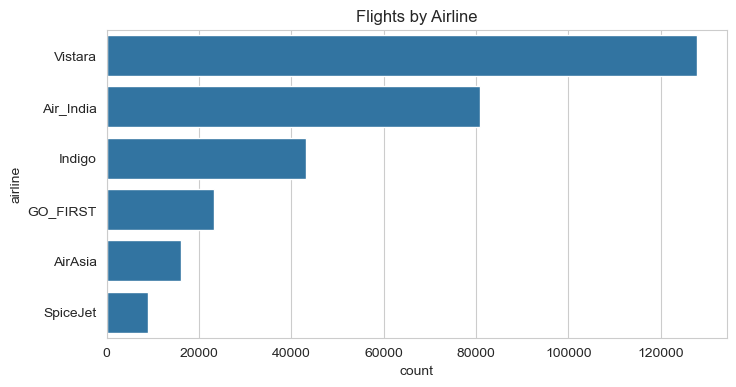

In [9]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, y="airline", order=df["airline"].value_counts().index)
plt.title("Flights by Airline")
plt.show()


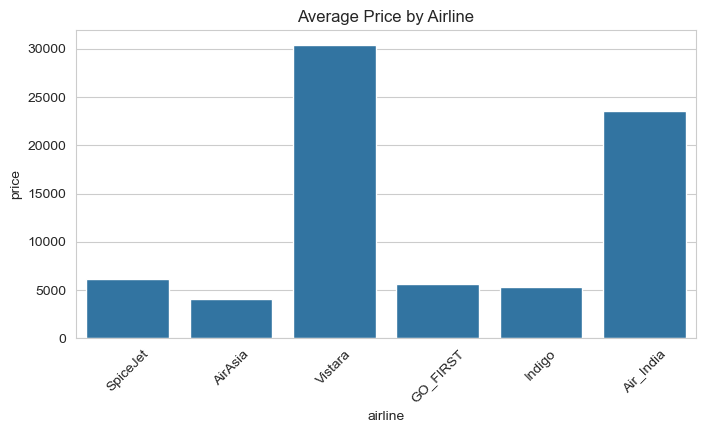

In [10]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="airline", y="price", errorbar=None)
plt.title("Average Price by Airline")
plt.xticks(rotation=45)
plt.show()


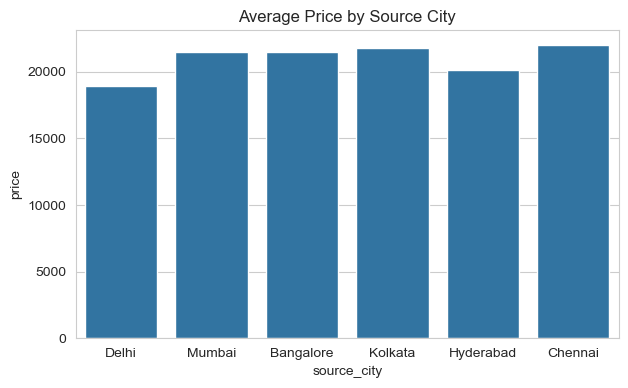

In [11]:
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="source_city", y="price", errorbar=None)
plt.title("Average Price by Source City")
plt.show()


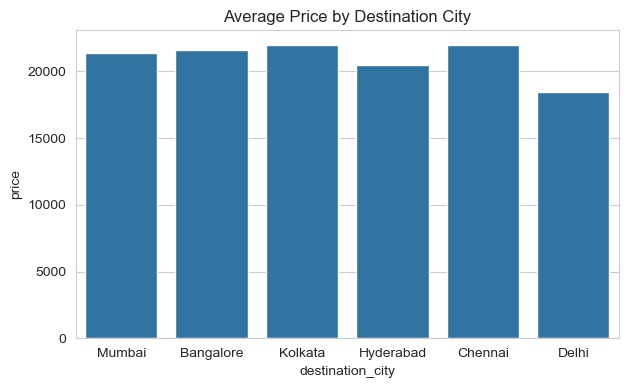

In [12]:
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="destination_city", y="price", errorbar=None)
plt.title("Average Price by Destination City")
plt.show()


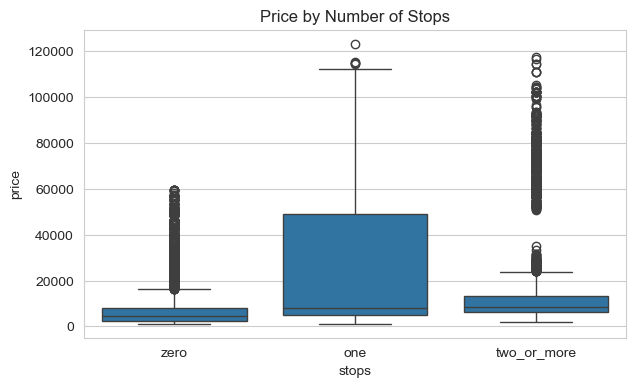

In [13]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="stops", y="price")
plt.title("Price by Number of Stops")
plt.show()


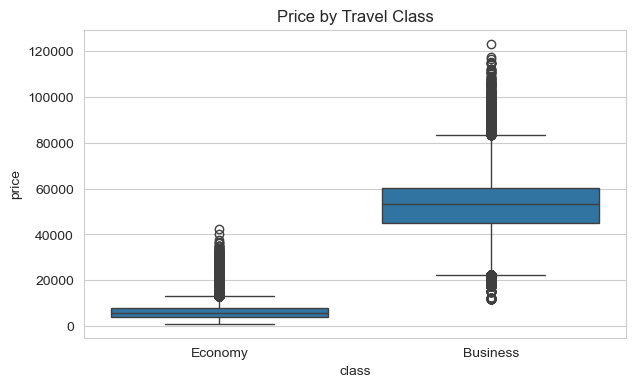

In [14]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="class", y="price")
plt.title("Price by Travel Class")
plt.show()


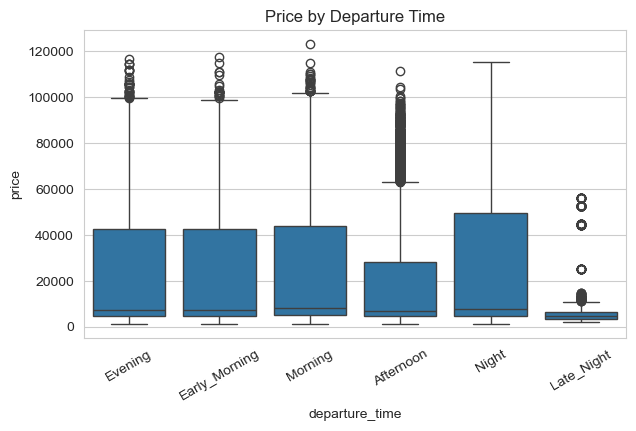

In [15]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="departure_time", y="price")
plt.title("Price by Departure Time")
plt.xticks(rotation=30)
plt.show()


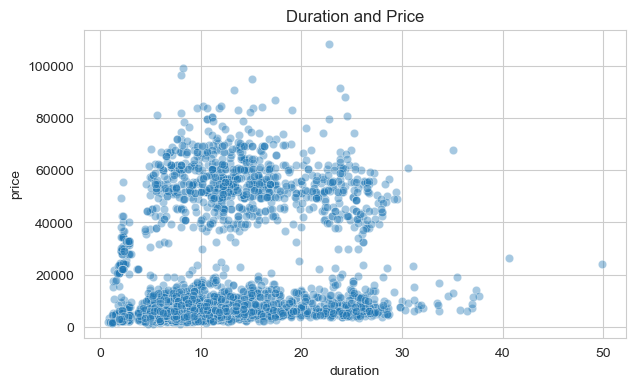

In [16]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=1),
                x="duration", y="price", alpha=0.4)
plt.title("Duration and Price")
plt.show()


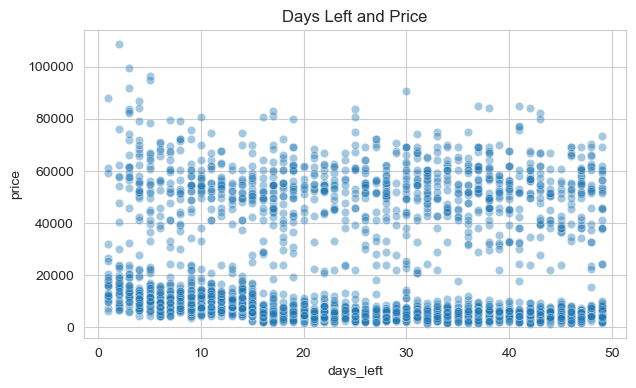

In [17]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=1),
                x="days_left", y="price", alpha=0.4)
plt.title("Days Left and Price")
plt.show()


In [18]:
print("Most common airline:", df["airline"].mode()[0])
print("Most common source city:", df["source_city"].mode()[0])
print("Most common destination city:", df["destination_city"].mode()[0])
print("Average price:", round(df["price"].mean(), 2))
print("Highest average fare class:", df.groupby("class")["price"].mean().idxmax())


Most common airline: Vistara
Most common source city: Delhi
Most common destination city: Mumbai
Average price: 20889.66
Highest average fare class: Business


## 4. Feature Engineering

In [19]:
# Convert stops into numbers
stop_map = {"zero": 0, "one": 1, "two_or_more": 2}
df["stops_num"] = df["stops"].astype(str).str.lower().str.strip().map(stop_map)
df["stops_num"] = df["stops_num"].fillna(df["stops_num"].mode()[0])


In [20]:
# Duration is already stored in hours in this dataset
df["duration"] = pd.to_numeric(df["duration"], errors="coerce")
df["duration"] = df["duration"].fillna(df["duration"].median())

df["days_left"] = pd.to_numeric(df["days_left"], errors="coerce")
df["days_left"] = df["days_left"].fillna(df["days_left"].median())


## 5. Encoding and Final Dataset

In [21]:
# Flight number is not used because it has many different values
df = df.drop(columns=["flight", "stops"], errors="ignore")

# Encode the category columns
category_cols = ["airline", "source_city", "departure_time",
                 "arrival_time", "destination_city", "class"]
df[category_cols] = df[category_cols].fillna("Unknown")
df = pd.get_dummies(df, columns=category_cols, dtype=int)


In [22]:
# Check the final data
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Text columns:", df.select_dtypes(include="object").columns.tolist())
print("Target column: price")
df.head()


Shape: (300153, 36)
Missing values: 0
Text columns: []
Target column: price


,duration,days_left,price,stops_num,airline_AirAsia,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,source_city_Bangalore,source_city_Chennai,source_city_Delhi,source_city_Hyderabad,source_city_Kolkata,source_city_Mumbai,departure_time_Afternoon,departure_time_Early_Morning,departure_time_Evening,departure_time_Late_Night,departure_time_Morning,departure_time_Night,arrival_time_Afternoon,arrival_time_Early_Morning,arrival_time_Evening,arrival_time_Late_Night,arrival_time_Morning,arrival_time_Night,destination_city_Bangalore,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai,class_Business,class_Economy
0,2.17,1,5953,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1
1,2.33,1,5953,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1
2,2.17,1,5956,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1
3,2.25,1,5955,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1
4,2.33,1,5955,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1


In [23]:
# Save the cleaned dataset
df.to_csv("flight_price_cleaned.csv", index=False)
print("File saved successfully.")


File saved successfully.


## Conclusion

In this assignment, I checked and explored the flight price dataset using Pandas, Matplotlib and Seaborn. I compared prices across airlines, cities, stops, travel class, departure time, duration and days left. I converted stops into numbers and used one-hot encoding for categorical columns. The final cleaned dataset was saved as a CSV file.

**Note:** This Kaggle file contains grouped departure and arrival times and does not contain the raw journey date or clock-time columns described in the assignment sheet. Therefore, those exact date and hour/minute features cannot be extracted from this file.